In [1]:
from pathlib import Path
import os
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
os.environ.setdefault('KERAS_HOME', str(Path.cwd() / '.keras'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from IPython.display import display


2026-10-26 23:10:44.249982: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1793036444.289840   43987 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793036444.303909   43987 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1793036444.336214   43987 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793036444.336270   43987 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793036444.336282   43987 computation_placer.cc:177] computation placer alr

In [2]:
SEED = 42
keras.utils.set_random_seed(SEED)
QUICK_RUN = False
print('TensorFlow:', tf.__version__)
print('GPUs:', tf.config.list_physical_devices('GPU'))

EPOCHS = 2 if QUICK_RUN else 50
SUBSET_SIZE = 1000 if QUICK_RUN else 4000
OUTPUT_DIR = Path('outputs/exp03')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


TensorFlow: 2.19.1
GPUs: []


E0000 00:00:1793036450.766400   43987 cuda_executor.cc:1228] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1793036450.772950   43987 gpu_device.cc:2341] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


In [3]:
def early_stopping(patience=5):
    return keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=patience,
        min_delta=1e-4,
        restore_best_weights=True,
        verbose=1,
    )


In [4]:
(x_pool, y_pool), (x_test, y_test) = keras.datasets.mnist.load_data()
x_pool, _, y_pool, _ = train_test_split(
    x_pool,
    y_pool,
    train_size=SUBSET_SIZE,
    stratify=y_pool,
    random_state=SEED,
)
x_train, x_val, y_train, y_val = train_test_split(
    x_pool,
    y_pool,
    test_size=0.2,
    stratify=y_pool,
    random_state=SEED,
)
if QUICK_RUN:
    x_test, y_test = (x_test[:1000], y_test[:1000])
x_train = x_train.astype('float32')[..., None] / 255.0
x_val = x_val.astype('float32')[..., None] / 255.0
x_test = x_test.astype('float32')[..., None] / 255.0
print('Train:', x_train.shape, 'Validation:', x_val.shape, 'Test:', x_test.shape)


Train: (3200, 28, 28, 1) Validation: (800, 28, 28, 1) Test: (10000, 28, 28, 1)


In [5]:
def build_cnn(regularized=False):
    penalty = regularizers.l2(1e-05) if regularized else None
    model = keras.Sequential(
        [layers.Input((28, 28, 1))],
        name='regularized' if regularized else 'baseline',
    )
    if regularized:
        model.add(layers.RandomRotation(0.028, fill_mode='constant', seed=SEED))
        model.add(layers.RandomTranslation(0.1, 0.1, fill_mode='constant', seed=SEED))
        model.add(layers.RandomZoom(0.1, fill_mode='constant', seed=SEED))
    for filters in (64, 128):
        model.add(
            layers.Conv2D(filters, 3, activation='relu', kernel_regularizer=penalty),
        )
        if regularized:
            model.add(layers.BatchNormalization())
        model.add(layers.MaxPooling2D())
    if regularized:
        model.add(layers.Dropout(0.2))
    model.add(layers.Flatten())
    for units in (512, 256):
        model.add(layers.Dense(units, activation='relu', kernel_regularizer=penalty))
        if regularized:
            model.add(layers.BatchNormalization())
            model.add(layers.Dropout(0.3))
    model.add(layers.Dense(10, activation='softmax'))
    model.compile(
        optimizer=keras.optimizers.Adam(0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'],
    )
    return model


In [6]:
def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    for ax, metric in zip(axes, ('accuracy', 'loss')):
        if metric not in history.history:
            ax.axis('off')
            continue
        epochs = np.arange(1, len(history.history[metric]) + 1)
        ax.plot(epochs, history.history[metric], label='Train')
        ax.plot(epochs, history.history['val_' + metric], label='Validation')
        ax.set(title=f'{title}: {metric}', xlabel='Epoch', ylabel=metric.title())
        ax.legend()
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{title.lower().replace(' ', '_')}_curves.png", dpi=150)
    plt.show()


Epoch 1/50
25/25 - 8s - 304ms/step - accuracy: 0.6803 - loss: 1.0365 - val_accuracy: 0.8550 - val_loss: 0.4985
Epoch 2/50
25/25 - 4s - 164ms/step - accuracy: 0.9134 - loss: 0.2759 - val_accuracy: 0.9250 - val_loss: 0.2344
Epoch 3/50
25/25 - 4s - 179ms/step - accuracy: 0.9506 - loss: 0.1491 - val_accuracy: 0.9413 - val_loss: 0.1936
Epoch 4/50
25/25 - 4s - 141ms/step - accuracy: 0.9669 - loss: 0.1000 - val_accuracy: 0.9538 - val_loss: 0.1618
Epoch 5/50
25/25 - 4s - 143ms/step - accuracy: 0.9828 - loss: 0.0591 - val_accuracy: 0.9588 - val_loss: 0.1536
Epoch 6/50
25/25 - 4s - 152ms/step - accuracy: 0.9869 - loss: 0.0414 - val_accuracy: 0.9600 - val_loss: 0.1520
Epoch 7/50
25/25 - 3s - 140ms/step - accuracy: 0.9903 - loss: 0.0319 - val_accuracy: 0.9625 - val_loss: 0.1467
Epoch 8/50
25/25 - 4s - 157ms/step - accuracy: 0.9872 - loss: 0.0403 - val_accuracy: 0.9638 - val_loss: 0.1356
Epoch 9/50
25/25 - 4s - 148ms/step - accuracy: 0.9875 - loss: 0.0308 - val_accuracy: 0.9600 - val_loss: 0.1260
E

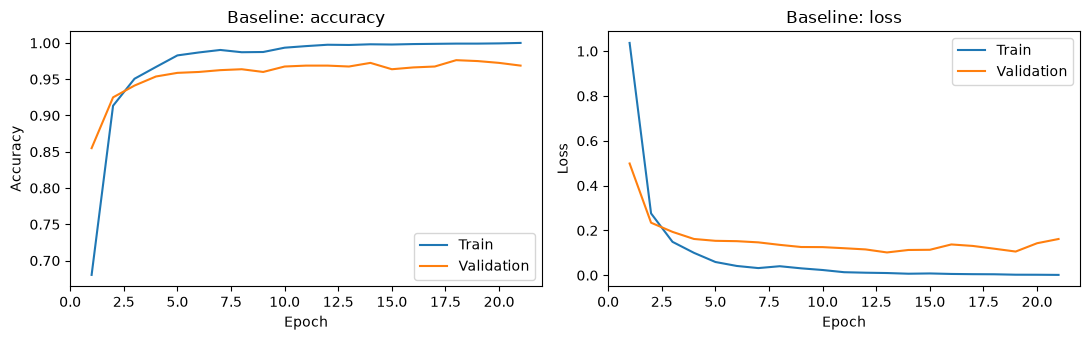

Epoch 1/50
25/25 - 14s - 558ms/step - accuracy: 0.6434 - loss: 1.2172 - val_accuracy: 0.4688 - val_loss: 2.0157 - learning_rate: 0.0010
Epoch 2/50
25/25 - 7s - 296ms/step - accuracy: 0.8441 - loss: 0.4968 - val_accuracy: 0.2188 - val_loss: 2.1505 - learning_rate: 0.0010
Epoch 3/50
25/25 - 8s - 302ms/step - accuracy: 0.8975 - loss: 0.3308 - val_accuracy: 0.2100 - val_loss: 2.4194 - learning_rate: 0.0010
Epoch 4/50
25/25 - 7s - 283ms/step - accuracy: 0.9284 - loss: 0.2453 - val_accuracy: 0.2075 - val_loss: 2.8414 - learning_rate: 0.0010
Epoch 5/50
25/25 - 7s - 268ms/step - accuracy: 0.9375 - loss: 0.2146 - val_accuracy: 0.2212 - val_loss: 3.0897 - learning_rate: 0.0010
Epoch 6/50
25/25 - 7s - 271ms/step - accuracy: 0.9434 - loss: 0.1841 - val_accuracy: 0.2313 - val_loss: 3.4226 - learning_rate: 5.0000e-04
Epoch 7/50
25/25 - 7s - 287ms/step - accuracy: 0.9509 - loss: 0.1747 - val_accuracy: 0.2150 - val_loss: 3.7144 - learning_rate: 5.0000e-04
Epoch 8/50
25/25 - 8s - 301ms/step - accuracy:

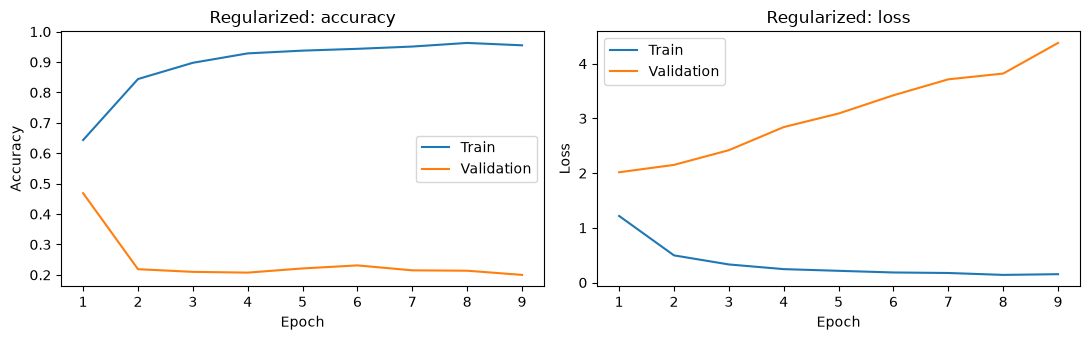

In [7]:
models = {}
histories = {}
rows = []
for name, use_regularization in (('Baseline', False), ('Regularized', True)):
    keras.utils.set_random_seed(SEED)
    model = build_cnn(use_regularization)
    callbacks = [early_stopping(patience=8)]
    if use_regularization:
        callbacks.append(
            keras.callbacks.ReduceLROnPlateau(patience=4, factor=0.5, min_lr=1e-05),
        )
    history = model.fit(
        x_train,
        y_train,
        validation_data=(x_val, y_val),
        epochs=EPOCHS,
        batch_size=128,
        callbacks=callbacks,
        verbose=2,
    )
    test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
    _, train_accuracy = model.evaluate(x_train, y_train, verbose=0)
    _, val_accuracy = model.evaluate(x_val, y_val, verbose=0)
    probabilities = model.predict(x_test, verbose=0)
    data_loss = float(
        np.mean(keras.losses.sparse_categorical_crossentropy(y_test, probabilities)),
    )
    rows.append(
        {
            'Model': name,
            'Epochs': len(history.history['loss']),
            'Test accuracy': test_accuracy,
            'Test cross-entropy': data_loss,
            'Test objective': test_loss,
            'Train accuracy (inference)': train_accuracy,
            'Validation accuracy': val_accuracy,
            'Train-validation gap': train_accuracy - val_accuracy,
        },
    )
    models[name], histories[name] = (model, history)
    plot_history(history, name)
    model.save(OUTPUT_DIR / f'{model.name}.keras')
    pd.DataFrame(history.history).to_csv(
        OUTPUT_DIR / f'{model.name}_history.csv',
        index=False,
    )


,Epochs,Test accuracy,Test cross-entropy,Test objective,Train accuracy (inference),Validation accuracy,Train-validation gap
Model,,,,,,,
Baseline,21,0.9726,0.1241,0.1251,0.9956,0.9675,0.0281
Regularized,9,0.4813,1.9962,2.0100,0.4597,0.4688,-0.0091


Test accuracy change: -0.4913
              precision    recall  f1-score   support

           0     0.9600    0.7592    0.8479       980
           1     0.3600    0.9947    0.5287      1135
           2     0.9945    0.1754    0.2982      1032
           3     0.0000    0.0000    0.0000      1010
           4     0.0000    0.0000    0.0000       982
           5     1.0000    0.0751    0.1397       892
           6     0.2982    0.9875    0.4581       958
           7     0.6020    0.8298    0.6978      1028
           8     0.9148    0.2864    0.4363       974
           9     0.6490    0.6085    0.6281      1009

    accuracy                         0.4813     10000
   macro avg     0.5779    0.4717    0.4035     10000
weighted avg     0.5718    0.4813    0.4078     10000



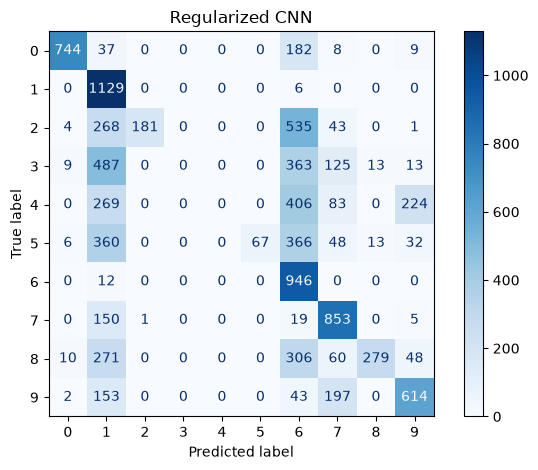

In [8]:
comparison = pd.DataFrame(rows).set_index('Model')
comparison.to_csv(OUTPUT_DIR / 'comparison.csv')
display(comparison.round(4))
print(
    'Test accuracy change:',
    round(
        float(
            (
                comparison.loc['Regularized', 'Test accuracy']
                - comparison.loc['Baseline', 'Test accuracy']
            ),
        ),
        4,
    ),
)
predictions = models['Regularized'].predict(x_test, verbose=0).argmax(axis=1)
print(classification_report(y_test, predictions, digits=4, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, predictions, cmap='Blues')
plt.title('Regularized CNN')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'confusion_matrix.png', dpi=150)
plt.show()
